# 1. Data and labels

This notebook looks at the OASIS-3 scans before any training: how many scans there are, which of the
44 FreeSurfer structures appear in them, how big each structure is, and what the two label sets look like.
It runs on CPU.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q monai nibabel

import os, sys, zipfile
DRIVE = '/content/drive/MyDrive'

# the wbseg code: use the folder in My Drive, or unpack wbseg.zip there the first time
if not os.path.exists(f'{DRIVE}/wbseg/__init__.py'):
    if os.path.exists(f'{DRIVE}/wbseg.zip'):
        zipfile.ZipFile(f'{DRIVE}/wbseg.zip').extractall(DRIVE)
        print('unpacked wbseg.zip into My Drive')
    else:
        raise SystemExit('wbseg not found. Upload wbseg.zip to My Drive (not inside any folder) and run this cell again.')
sys.path.insert(0, DRIVE)
import wbseg
print('using wbseg from', os.path.dirname(wbseg.__file__))

OUT_DIR = f'{DRIVE}/wbseg_outputs'   # results and figures are saved here
os.makedirs(OUT_DIR, exist_ok=True)
os.chdir(OUT_DIR)

Mounted at /content/drive
using wbseg from /content/drive/MyDrive/wbseg


In [2]:
IMAGE_DIR = "/content/drive/MyDrive/OASIS3_Dataset_Part4-20240506T062954Z-001/OASIS3_Dataset_Part4/Image_Folder"
LABEL_DIR = "/content/drive/MyDrive/OASIS3_Dataset_Part4-20240506T062954Z-001/OASIS3_Dataset_Part4/Label_Folder"
LUT_PATH = "/content/drive/MyDrive/FreeSurferColorLUT.txt"   # optional, only for FreeSurfer colours

if not os.path.exists(LUT_PATH):
    LUT_PATH = None
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

In [3]:
import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from wbseg.data import find_pairs
from wbseg.labels import FULL_LABELS, REDUCED_LABELS, NAMES, colour_table
from wbseg.volumes import label_volumes
from wbseg import plots


## Scans

In [4]:
pairs = find_pairs(IMAGE_DIR, LABEL_DIR)
print(len(pairs), "image / label pairs")
img = nib.load(pairs[0]["image"])
print("shape", img.shape, " voxel size (mm)", img.header.get_zooms()[:3])

found 148 images in /content/drive/MyDrive/OASIS3_Dataset_Part4-20240506T062954Z-001/OASIS3_Dataset_Part4/Image_Folder
found 148 label maps in /content/drive/MyDrive/OASIS3_Dataset_Part4-20240506T062954Z-001/OASIS3_Dataset_Part4/Label_Folder
148 image / label pairs
shape (256, 256, 256)  voxel size (mm) (np.float32(1.0), np.float32(1.0), np.float32(1.0))


## The two label sets

The full set has every aseg structure present in the data (44 structures + background = 45 classes).
The reduced set keeps 27 structures. It leaves out the very small ones (amygdala, accumbens, inferior
lateral ventricles, vessels, optic chiasm, the five corpus callosum segments) and the ones without a clear
anatomical boundary (CSF and the white matter hypointensities, which are lesion-like and vary a lot between people).
All 44 structures appear in every one of the 148 scans.

In [5]:
dropped = [l for l in FULL_LABELS[1:] if l not in REDUCED_LABELS]
print("classes:", len(FULL_LABELS), "full,", len(REDUCED_LABELS), "reduced")
print("left out of the reduced set:")
for l in dropped:
    print(f"  {l:4d}  {NAMES[l]}")

classes: 45 full, 28 reduced
left out of the reduced set:
     5  Left-Inf-Lat-Vent
    18  Left-Amygdala
    24  CSF
    26  Left-Accumbens-area
    30  Left-vessel
    44  Right-Inf-Lat-Vent
    54  Right-Amygdala
    58  Right-Accumbens-area
    62  Right-vessel
    77  WM-hypointensities
    80  non-WM-hypointensities
    85  Optic-Chiasm
   251  CC_Posterior
   252  CC_Mid_Posterior
   253  CC_Central
   254  CC_Mid_Anterior
   255  CC_Anterior


## Structure sizes

Volume of every structure in every scan, straight from the FreeSurfer label maps. This shows how unbalanced
the problem is: the largest structures are thousands of times bigger than the smallest ones.

In [6]:
rows = []
for p in pairs:
    for lab, vol in label_volumes(p["label"], FULL_LABELS).items():
        rows.append({"id": p["id"], "label": lab, "structure": NAMES[lab], "volume_ml": vol})
vols = pd.DataFrame(rows)

sizes = (vols.groupby(["label", "structure"])["volume_ml"]
         .agg(median_ml="median", present_in=lambda v: int((v > 0).sum()))
         .reset_index().sort_values("median_ml", ascending=False))
sizes["in_reduced_set"] = sizes["label"].isin(REDUCED_LABELS)
sizes.to_csv("results/structure_sizes.csv", index=False)

present = sizes[sizes.median_ml > 0]
big, small = present.iloc[0], present.iloc[-1]
print(f"largest:  {big.structure} {big.median_ml:.1f} ml")
print(f"smallest: {small.structure} {small.median_ml:.3f} ml  ({big.median_ml / small.median_ml:,.0f} times smaller)")
print(f"structures present in all {len(pairs)} scans: {(sizes.present_in == len(pairs)).sum()} of {len(sizes)}")
sizes

largest:  Right-Cerebral-Cortex 207.1 ml
smallest: non-WM-hypointensities 0.062 ml  (3,368 times smaller)
structures present in all 148 scans: 44 of 44


,label,structure,median_ml,present_in,in_reduced_set
21,42,Right-Cerebral-Cortex,207.131025,148,True
1,3,Left-Cerebral-Cortex,201.420994,148,True
0,2,Left-Cerebral-White-Matter,190.653977,148,True
20,41,Right-Cerebral-White-Matter,188.912000,148,True
25,47,Right-Cerebellum-Cortex,45.725500,148,True
5,8,Left-Cerebellum-Cortex,43.981997,148,True
12,16,Brain-Stem,19.838498,148,True
2,4,Left-Lateral-Ventricle,15.016002,148,True
24,46,Right-Cerebellum-White-Matter,13.630500,148,True
4,7,Left-Cerebellum-White-Matter,13.333001,148,True


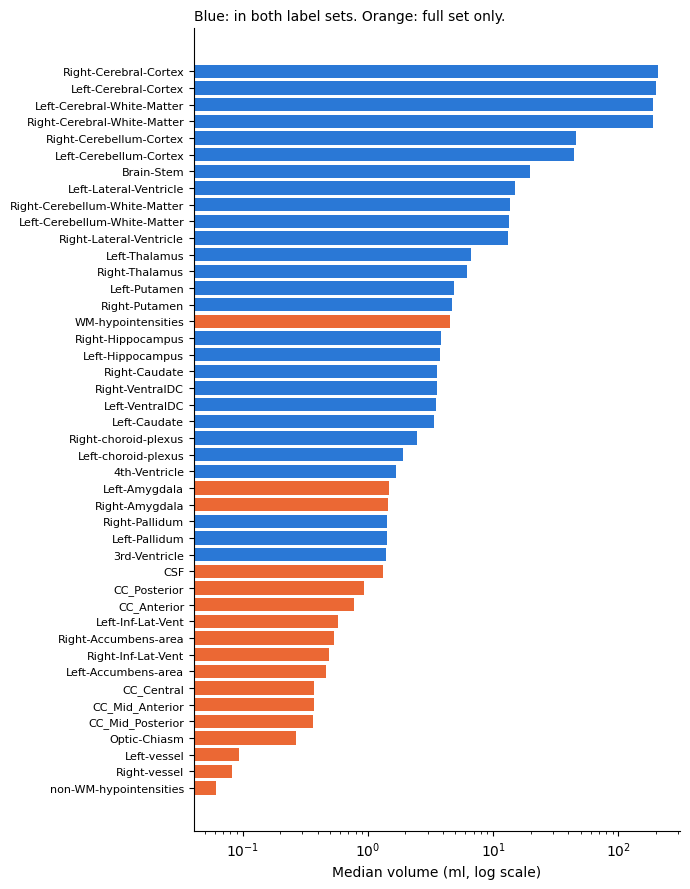

In [7]:
fig, ax = plt.subplots(figsize=(7, 9))
s = sizes.sort_values("median_ml")
colour = np.where(s["in_reduced_set"], plots.BLUE, plots.ORANGE)
ax.barh(s["structure"], s["median_ml"], color=colour)
ax.set_xscale("log")
ax.set_xlabel("Median volume (ml, log scale)")
ax.tick_params(axis="y", labelsize=8)
ax.set_title("Blue: in both label sets. Orange: full set only.", loc="left", fontsize=10)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig("figures/structure_sizes.png", dpi=150)
plt.show()

## Example scan with both label sets

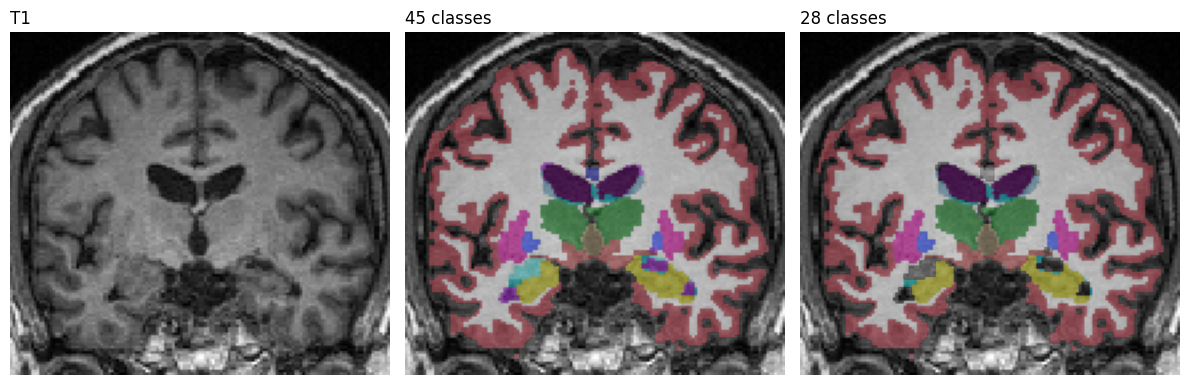

In [8]:
img = nib.as_closest_canonical(nib.load(pairs[0]["image"]))
lab = nib.as_closest_canonical(nib.load(pairs[0]["label"]))
image, label = img.get_fdata(), np.asarray(lab.dataobj).astype(int)
reduced = np.where(np.isin(label, REDUCED_LABELS), label, 0)

k = image.shape[1] // 2     # middle coronal slice
box = plots.brain_box(label, axis=1, index=k)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.4))
plots.overlay(image, label, FULL_LABELS, colour_table(FULL_LABELS), axis=1, index=k, ax=axes[0], box=box, alpha=0)
axes[0].set_title("T1", loc="left")
plots.overlay(image, label, FULL_LABELS, colour_table(FULL_LABELS, LUT_PATH), axis=1, index=k, ax=axes[1], box=box)
axes[1].set_title("45 classes", loc="left")
plots.overlay(image, reduced, REDUCED_LABELS, colour_table(REDUCED_LABELS, LUT_PATH), axis=1, index=k, ax=axes[2], box=box)
axes[2].set_title("28 classes", loc="left")
fig.tight_layout()
fig.savefig("figures/label_sets.png", dpi=150)
plt.show()